# Red neuronal de regresión: níquel a partir de los óxidos mayores

**Unidad 4 · Machine Learning** · Geoquímica de rocas con datos de EarthChem PetDB · Estadística y Probabilidades,
FIGEMPA – UCE. Proyecto estrictamente académico.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/crisrumiguano-art/geoquimica-earthchem-ml/blob/main/notebooks/01_regresion_niquel.ipynb)

Estimar la concentración de **níquel (ppm)**, un metal crítico, con los 8 óxidos mayores de la roca.

**Cómo usarlo:** en Colab, *Entorno de ejecución → Ejecutar todas*. Tarda unos minutos.

## 0. De la regresión clásica a la red neuronal

En la Unidad 3 el níquel se explicó con **una** variable (MgO) y una curva elegida a mano. Una **red neuronal** es una
regresión con muchas variables a la vez y sin elegir la forma de la curva: aprende la forma sola.

- Una **neurona** hace lo mismo que una regresión lineal múltiple, y = w₁x₁ + w₂x₂ + … + b, y después aplica una
  **función de activación** (ReLU: si el resultado es negativo da 0). La activación es lo que permite curvas.
- Muchas neuronas en **capas** forman la red. La idea viene de McCulloch y Pitts (1943) y del perceptrón de Rosenblatt
  (1958); la **retropropagación** (1986) es el método para entrenarla: se calcula el error, se ve cuánto aporta cada peso
  y se lo corrige un poco (**descenso del gradiente**). Cada pasada completa por los datos es una **época**.

**Problema:** el níquel es un metal crítico. ¿Se puede estimar el Ni de una roca a partir de sus óxidos mayores, que se
miden en casi todos los análisis?

## 1. Librerías y carga de datos

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(2026)        # semilla: los resultados se pueden repetir

# Base de datos: si se corre en el repositorio usa la copia local; en Colab la descarga de GitHub (26 MB)
local = "../data/earthchem_limpio.csv.gz"
url = "https://github.com/crisrumiguano-art/geoquimica-earthchem-ml/raw/main/data/earthchem_limpio.csv.gz"
base = pd.read_csv(local if os.path.exists(local) else url, low_memory=False)
print(base.shape)

# Las figuras se guardan para la web solo cuando se corre dentro del repositorio
WEB = "../docs/img/ml" if os.path.isdir("../docs") else None
if WEB:
    os.makedirs(WEB, exist_ok=True)
def guardar(nombre):
    if WEB:
        plt.savefig(f"{WEB}/{nombre}.png", dpi=130, bbox_inches="tight")

(159760, 75)


## 2. Preprocesamiento

- Variables de entrada: los 8 óxidos mayores. Salida: **log10(Ni)**, porque el níquel va de menos de 1 a miles de ppm
  (igual que en la Unidad 3, los logaritmos hacen que todos los órdenes de magnitud pesen igual).
- Solo filas con todo completo: no se inventa ningún dato.
- **División**: 70 % entrenamiento, 15 % validación (para elegir hiperparámetros y parar a tiempo) y 15 % prueba (solo
  al final, para medir el resultado con datos que la red nunca vio).
- **Normalización**: cada variable se lleva a media 0 y desviación 1 con los datos de entrenamiento.

In [2]:
ENTRADAS = ["SiO2 (wt%)", "Al2O3 (wt%)", "MgO (wt%)", "CaO (wt%)", "Na2O (wt%)", "K2O (wt%)", "P2O5 (wt%)", "MnO (wt%)"]
datos = base[ENTRADAS + ["Ni (ppm)"]].dropna()
datos = datos[datos["Ni (ppm)"] > 0]
X = datos[ENTRADAS].values
y = np.log10(datos["Ni (ppm)"].values)
print("filas completas:", len(datos))

X_ent, X_resto, y_ent, y_resto = train_test_split(X, y, test_size=0.30, random_state=2026)
X_val, X_prueba, y_val, y_prueba = train_test_split(X_resto, y_resto, test_size=0.50, random_state=2026)
escala = StandardScaler().fit(X_ent)              # se ajusta SOLO con entrenamiento
X_ent, X_val, X_prueba = escala.transform(X_ent), escala.transform(X_val), escala.transform(X_prueba)
print("entrenamiento:", len(y_ent), " validación:", len(y_val), " prueba:", len(y_prueba))

filas completas: 7133
entrenamiento: 4993  validación: 1070  prueba: 1070


## 3. Optimización de hiperparámetros con Optuna

Los **hiperparámetros** son las decisiones de diseño: cuántas capas, cuántas neuronas, qué tan rápido aprende. En vez de
probar a mano, **Optuna** prueba combinaciones y se queda con la que da menor error en validación (prueba y error
automático).

In [3]:
%pip install -q optuna
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def crear_red(capas, neuronas, tasa, abandono):
    red = keras.Sequential([layers.Input(shape=(X_ent.shape[1],))])
    for i in range(capas):
        red.add(layers.Dense(max(neuronas // (2 ** i), 8), activation="relu"))   # cada capa con la mitad de neuronas
        red.add(layers.Dropout(abandono))            # apaga neuronas al azar: evita memorizar (sobreajuste)
    red.add(layers.Dense(1))                         # una salida: log10(Ni)
    red.compile(optimizer=keras.optimizers.Adam(tasa), loss="mse", metrics=["mae"])
    return red

def objetivo(prueba):
    capas = prueba.suggest_int("capas", 1, 3)
    neuronas = prueba.suggest_categorical("neuronas", [32, 64, 128])
    tasa = prueba.suggest_float("tasa_aprendizaje", 1e-4, 1e-2, log=True)
    abandono = prueba.suggest_float("abandono", 0.0, 0.3)
    red = crear_red(capas, neuronas, tasa, abandono)
    h = red.fit(X_ent, y_ent, validation_data=(X_val, y_val), epochs=40, batch_size=256, verbose=0,
                callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    return min(h.history["val_loss"])

estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=2026))
estudio.optimize(objetivo, n_trials=20)
print("mejores hiperparámetros:", estudio.best_params)
print("error de validación (MSE):", round(estudio.best_value, 4))


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\dalem\venv-geoml\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


mejores hiperparámetros: {'capas': 2, 'neuronas': 32, 'tasa_aprendizaje': 0.0030084307818340223, 'abandono': 0.012648958797537795}
error de validación (MSE): 0.0611


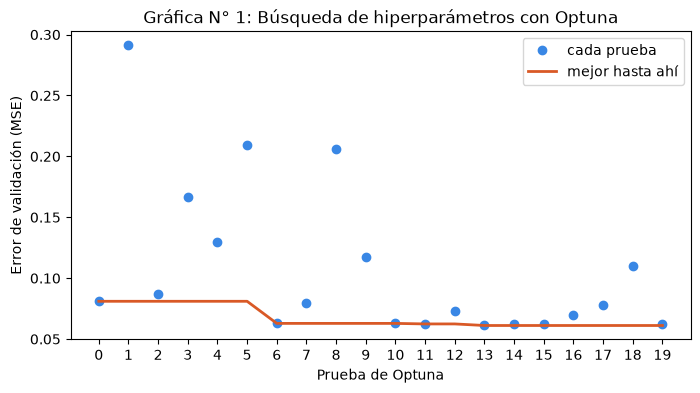

In [4]:
pruebas = estudio.trials_dataframe()
plt.figure(figsize=(8, 4))
plt.plot(pruebas["number"], pruebas["value"], "o", color="#3987e5", label="cada prueba")
plt.plot(pruebas["number"], pruebas["value"].cummin(), color="#d95926", lw=2, label="mejor hasta ahí")
plt.xticks(pruebas["number"])
plt.xlabel("Prueba de Optuna"); plt.ylabel("Error de validación (MSE)"); plt.legend()
plt.title("Gráfica N° 1: Búsqueda de hiperparámetros con Optuna")
guardar("reg_optuna"); plt.show()

## 4. Entrenamiento con los mejores hiperparámetros

In [5]:
p = estudio.best_params
red = crear_red(p["capas"], p["neuronas"], p["tasa_aprendizaje"], p["abandono"])
red.summary()
historia = red.fit(X_ent, y_ent, validation_data=(X_val, y_val), epochs=150, batch_size=256, verbose=0,
                   callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)])
print("épocas entrenadas:", len(historia.history["loss"]))

Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_61 (Dense)                │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_63 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

épocas entrenadas: 96


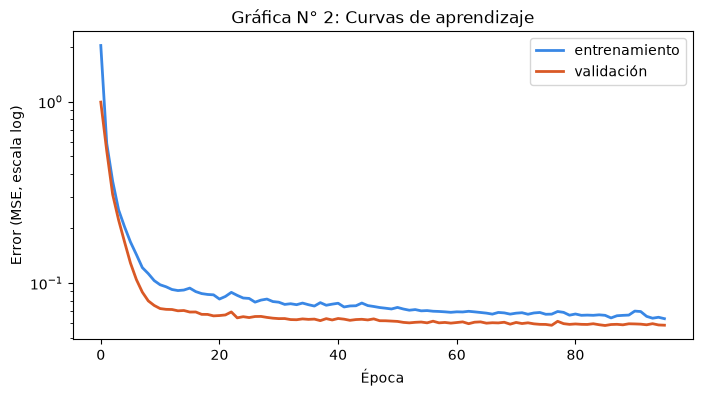

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(historia.history["loss"], color="#3987e5", lw=2, label="entrenamiento")
plt.plot(historia.history["val_loss"], color="#d95926", lw=2, label="validación")
plt.yscale("log")                                # escala log: se ve también el final, no solo la caída inicial
plt.xlabel("Época"); plt.ylabel("Error (MSE, escala log)"); plt.legend()
plt.title("Gráfica N° 2: Curvas de aprendizaje")
guardar("reg_curvas"); plt.show()

Si las dos curvas bajan juntas y se estabilizan, la red aprendió sin **sobreajuste** (memorizar el entrenamiento).
Si la de validación subiera mientras la de entrenamiento baja, habría sobreajuste; si las dos quedaran altas,
**subajuste** (la red es demasiado simple).

## 5. Evaluación con los datos de prueba

R² = 0.835   RMSE = 0.235 (log10)   MAE = 0.163 (log10)
En ppm, el error típico es un factor de 1.46 (el Ni estimado suele estar entre /1.46 y x1.46 del real)


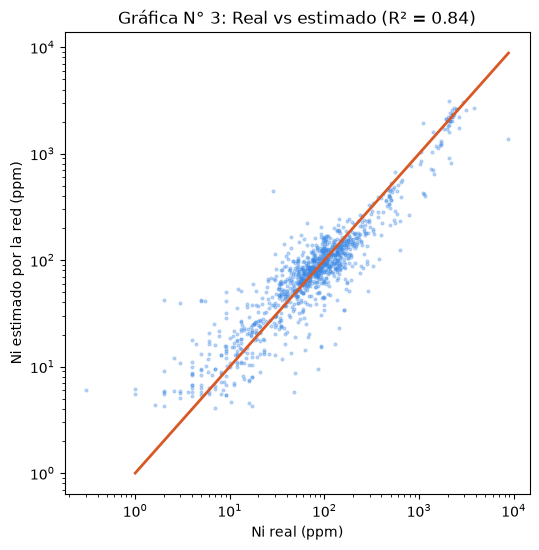

In [7]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
pred = red.predict(X_prueba, verbose=0).ravel()
r2 = r2_score(y_prueba, pred)
rmse = mean_squared_error(y_prueba, pred) ** 0.5
mae = mean_absolute_error(y_prueba, pred)
print(f"R² = {r2:.3f}   RMSE = {rmse:.3f} (log10)   MAE = {mae:.3f} (log10)")
print(f"En ppm, el error típico es un factor de {10 ** mae:.2f} (el Ni estimado suele estar entre /{10 ** mae:.2f} y x{10 ** mae:.2f} del real)")

plt.figure(figsize=(6, 6))
plt.scatter(10 ** y_prueba, 10 ** pred, s=4, alpha=0.3, color="#3987e5")
lim = [1, 10 ** max(y_prueba.max(), pred.max())]
plt.plot(lim, lim, color="#d95926", lw=2)
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Ni real (ppm)"); plt.ylabel("Ni estimado por la red (ppm)")
plt.title(f"Gráfica N° 3: Real vs estimado (R² = {r2:.2f})")
guardar("reg_real_vs_estimado"); plt.show()

## 6. Comparación con la Unidad 3

El mismo problema con los modelos clásicos: el mejor modelo de **una** variable (Ni en función de MgO, como en la
Unidad 3) y una regresión lineal múltiple con los 8 óxidos. Se evalúan con los mismos datos de prueba.

                          modelo    R2
Exponencial: Ni ~ MgO (Unidad 3) 0.579
       Lineal múltiple: 8 óxidos 0.693
          Red neuronal: 8 óxidos 0.835


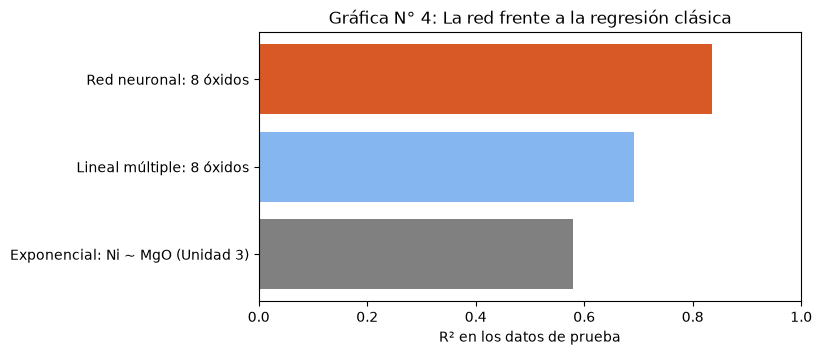

In [8]:
from sklearn.linear_model import LinearRegression
i_mgo = ENTRADAS.index("MgO (wt%)")
una = LinearRegression().fit(X_ent[:, [i_mgo]], y_ent)          # log Ni = a + b·MgO (modelo exponencial)
multiple = LinearRegression().fit(X_ent, y_ent)                # regresión lineal múltiple
comparacion = pd.DataFrame({
    "modelo": ["Exponencial: Ni ~ MgO (Unidad 3)", "Lineal múltiple: 8 óxidos", "Red neuronal: 8 óxidos"],
    "R2": [r2_score(y_prueba, una.predict(X_prueba[:, [i_mgo]])), r2_score(y_prueba, multiple.predict(X_prueba)), r2]})
print(comparacion.round(3).to_string(index=False))
plt.figure(figsize=(7, 3.5))
plt.barh(comparacion["modelo"], comparacion["R2"], color=["gray", "#86b6ef", "#d95926"])
plt.xlim(0, 1); plt.xlabel("R² en los datos de prueba")
plt.title("Gráfica N° 4: La red frente a la regresión clásica")
guardar("reg_comparacion"); plt.show()

## 7. Predicción interactiva

In [9]:
import ipywidgets as widgets
from IPython.display import display
valores_basalto = [50.0, 15.0, 8.0, 11.0, 2.5, 0.3, 0.2, 0.17]          # un basalto típico de dorsal
casillas = [widgets.FloatText(value=v, description=n.split(" ")[0], layout=widgets.Layout(width="200px"))
            for n, v in zip(ENTRADAS, valores_basalto)]
boton = widgets.Button(description="Estimar Ni", button_style="warning")
salida = widgets.Output()
def estimar(_):
    with salida:
        salida.clear_output()
        x = escala.transform([[c.value for c in casillas]])
        print(f"Ni estimado: {10 ** red.predict(x, verbose=0)[0, 0]:.0f} ppm")
boton.on_click(estimar)
display(widgets.VBox(casillas + [boton, salida]))
estimar(None)

In [10]:
# Ejemplos sin widgets: un basalto y una peridotita
ejemplos = pd.DataFrame([valores_basalto, [44.0, 2.0, 42.0, 1.5, 0.1, 0.02, 0.01, 0.12]], columns=ENTRADAS,
                        index=["basalto", "peridotita"])
ejemplos["Ni estimado (ppm)"] = 10 ** red.predict(escala.transform(ejemplos[ENTRADAS].values), verbose=0).ravel()
print(ejemplos.round(1).to_string())
if WEB:
    json.dump({"regresion": {"n": int(len(datos)), "r2": round(float(r2), 3), "rmse_log": round(float(rmse), 3),
                             "mae_log": round(float(mae), 3), "hiperparametros": {k: (round(v, 5) if isinstance(v, float) else v) for k, v in p.items()},
                             "comparacion": comparacion.round(3).to_dict("records"),
                             "ejemplos": ejemplos["Ni estimado (ppm)"].round(0).to_dict()}},
              open("../docs/data/ml_regresion.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

            SiO2 (wt%)  Al2O3 (wt%)  MgO (wt%)  CaO (wt%)  Na2O (wt%)  K2O (wt%)  P2O5 (wt%)  MnO (wt%)  Ni estimado (ppm)
basalto           50.0         15.0        8.0       11.0         2.5        0.3         0.2        0.2         125.199997
peridotita        44.0          2.0       42.0        1.5         0.1        0.0         0.0        0.1        2097.500000


## 8. Conclusión

La red neuronal estima el **log10 del níquel** a partir de los ocho óxidos mayores con un R² cercano a 0,8 en datos que
nunca vio, bastante más que el mejor modelo de una sola variable de la Unidad 3 y que la regresión lineal múltiple. La
diferencia viene de que la red combina los óxidos de forma no lineal: el Ni depende sobre todo del olivino (MgO), pero el
SiO₂, el CaO y el Al₂O₃ ayudan a separar peridotitas, basaltos y rocas evolucionadas. Límites: solo vale para rocas
parecidas a las de PetDB (sobre todo oceánicas) y su error típico es de un factor cercano a 1,5 en ppm (el Ni estimado
suele estar entre dos tercios y una vez y media del real).